# 03 快速分析（读 PostgreSQL）
不需要连 TWS。数据来自 `bars` 表，五只 ETF 2019 年至今日线。

In [1]:
import pandas as pd, matplotlib.pyplot as plt
from ibkr_quant.db import read_closes, engine
from ibkr_quant.analysis.returns import summary, simple_returns
import sqlalchemy as sa

ETFS = ['SPY', 'QQQ', 'IWM', 'TLT', 'GLD']
pd.read_sql(sa.text('select symbol, count(*) as rows, min(ts)::date as first, max(ts)::date as last from bars group by 1 order by 1'), engine)

,symbol,rows,first,last
0,GLD,1969,2019-01-02,2026-10-30
1,IWM,1969,2019-01-02,2026-10-30
2,QQQ,1969,2019-01-02,2026-10-30
3,SPY,1969,2019-01-02,2026-10-30
4,TLT,1969,2019-01-02,2026-10-30


In [2]:
closes = read_closes(ETFS).dropna()
closes.index = closes.index.tz_localize(None)
closes.tail()

symbol,GLD,IWM,QQQ,SPY,TLT
ts,,,,,
2026-10-26,367.82,276.99,712.20,765.37,81.68
2026-10-27,372.28,280.18,721.25,769.66,81.63
2026-10-28,373.51,281.29,725.61,772.31,80.99
2026-10-29,368.57,284.01,715.34,769.36,81.49
2026-10-30,355.78,279.33,690.49,755.72,81.84


In [3]:
summary(closes).round(4)

,ann_return,ann_vol,sharpe,max_drawdown
symbol,,,,
GLD,0.1477,0.1785,0.8276,-0.2826
IWM,0.0979,0.2475,0.3957,-0.4107
QQQ,0.2109,0.2388,0.8835,-0.3562
SPY,0.1521,0.1923,0.7909,-0.3410
TLT,-0.0500,0.1591,-0.3143,-0.5506


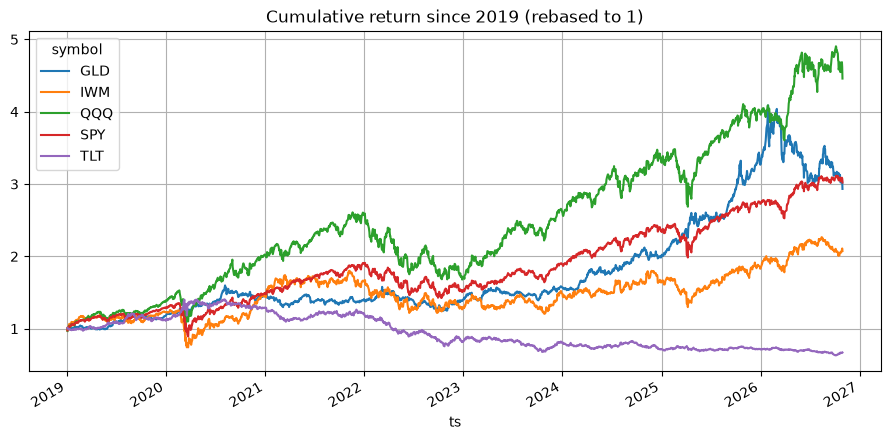

In [4]:
nav = (1 + simple_returns(closes)).cumprod()
nav.plot(figsize=(11,5), grid=True, title='Cumulative return since 2019 (rebased to 1)');

In [5]:
simple_returns(closes).corr().round(3)

symbol,GLD,IWM,QQQ,SPY,TLT
symbol,,,,,
GLD,1.000,0.139,0.152,0.133,0.223
IWM,0.139,1.000,0.761,0.862,-0.089
QQQ,0.152,0.761,1.000,0.932,-0.077
SPY,0.133,0.862,0.932,1.000,-0.125
TLT,0.223,-0.089,-0.077,-0.125,1.000


In [6]:
# 按年收益
yearly = closes.resample('YE').last().pct_change().dropna()
yearly.index = yearly.index.year
(yearly*100).round(1)

symbol,GLD,IWM,QQQ,SPY,TLT
ts,,,,,
2020,24.8,18.3,47.6,16.2,16.4
2021,-4.1,13.5,26.8,27.0,-6.0
2022,-0.8,-21.6,-33.1,-19.5,-32.8
2023,12.7,15.1,53.8,24.3,-0.7
2024,26.7,10.1,24.8,23.3,-11.7
2025,63.7,11.4,20.2,16.4,-0.2
2026,-10.2,13.5,12.4,10.8,-6.1
